# Sales Performance & Customer Insights
### Python Programming Data Analyst Capstone — Option A

**Business question:** How is the store performing, and what drives revenue?

**Dataset:** Synthetic Philippine retail/e-commerce training dataset containing seven related CSV files. The dataset is provided in the course materials and is used as-is; no external data was added.

**Scope:** Data loading and quality checks; documented cleaning; an item-level sales fact table; revenue and customer KPIs; five required visualizations; business insights and recommendations.

**Important analytical definition:** Merchandise revenue is calculated from valid order-item quantities and purchase prices after the order-level discount. Shipping fees, payment amounts, and refunds are excluded from this revenue measure because payment amounts are intentionally inconsistent with computed order totals and refund records may be incomplete. Sales KPIs include orders with status **Completed** or **Shipped**; Pending, Cancelled, and Returned orders are excluded from recognized merchandise sales. This rule is explicit and can be adjusted if the instructor specifies another definition.

> Run the notebook from its project folder so the relative `data/` and `output/` paths work. All cleaning choices are documented below.

## 1. Setup and imports

In [2]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "output"
CHART_DIR = OUTPUT_DIR / "charts"
OUTPUT_DIR.mkdir(exist_ok=True)
CHART_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 10


In [ ]:
%pip install numpy pandas matplotlib

## 2. Load all seven CSV files

In [3]:
file_names = ["customers", "orders", "products", "order_items", "payments", "returns", "shipments"]
raw = {name: pd.read_csv(DATA_DIR / f"{name}.csv") for name in file_names}

for name, df in raw.items():
    print(f"{name:12s} | rows: {len(df):,} | columns: {len(df.columns)}")
    display(df.head(3))


customers    | rows: 5,050 | columns: 13


,customer_id,first_name,last_name,gender,age,email,phone,region_code,region_name,city,barangay,signup_date,loyalty_tier
0,CUST000001,Grace,DelosReyes,NaN,20.00,grace.delosreyes95@outlook.com,"9,196,001,338.00",Region III,Central Luzon,Angeles,Brgy 1,2025-12-31,Bronze
1,CUST000002,Ana,Ramos,Female,35.00,ana.ramos@companymail.ph,"9,026,542,351.00",CARAGA,Caraga,Butuan,Brgy 9,2025-02-08,Bronze
2,CUST000003,Arvin,Navarro,Male,14.00,arvin.navarrooutlook.com,"9,161,849,593.00",NCR,Metro Manila,Pasig,Brgy 2,2023-09-10,Bronze


orders       | rows: 15,075 | columns: 8


,order_id,customer_id,order_datetime,order_status,sales_channel,shipping_method,discount_pct,shipping_fee
0,ORD0000001,CUST000839,2025-11-07 17:02:00,Cancelled,Marketplace,Standard,0.07,102.68
1,ORD0000002,CUST002871,09/18/2025 09:13 AM,Completed,Marketplace,Express,0.06,0.00
2,ORD0000003,CUST000720,2025-08-08 04:59:00,Completed,Web,Standard,0.14,103.83


products     | rows: 800 | columns: 9


,product_id,product_name,brand,category,unit_cost,unit_price,stock_qty,uom,launch_date
0,PROD00001,KidJoy Beauty 963,KidJoy,Beauty,44.17,64.5,125.00,pc,2022-01-18
1,PROD00002,HomeEase Home 368,HomeEase,Home and Kitchen,37.18,70.39,131.00,pcs,2022-11-25
2,PROD00003,FreshCart Fashion 911,FreshCart,Fashion,46.29,₱70.26,41.00,piece,2023-09-04


... (4 outputs left out)

returns      | rows: 1,200 | columns: 6


,return_id,order_id,return_request_date,reason,refunded_flag,refund_amount
0,RET000001,ORD0008752,2025-01-09,Defective,No,NaN
1,RET000002,ORD0007359,2025-07-20,Wrong item,NaN,650.28
2,RET000003,ORD0009041,01/07/2025,Size issue,Yes,NaN


shipments    | rows: 15,000 | columns: 7


,shipment_id,order_id,courier,tracking_no,shipment_status,ship_date,delivered_date
0,SHP0000001,ORD0000001,J&T,HLI2ORMO9V4O,Delivered,2025-09-05,09/06/2025
1,SHP0000002,ORD0000002,NinjaVan,E8XLRMV7QVEB,In Transit,2025-02-06,2025-02-12
2,SHP0000003,ORD0000003,2GO,LHLXVJF18MQB,Delivered,2025-07-23,2025-07-29


## 3. Initial data profiling

In [4]:
profile_rows = []
for name, df in raw.items():
    profile_rows.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns),
        "exact_duplicate_rows": int(df.duplicated().sum()),
        "missing_cells": int(df.isna().sum().sum()),
    })
profile = pd.DataFrame(profile_rows)
display(profile)

# Inspect key fields and raw category/status values before cleaning.
for name, col in [("products", "category"), ("orders", "order_status"),
                  ("shipments", "shipment_status"), ("returns", "reason"),
                  ("payments", "payment_status")]:
    print(f"\n{name}.{col}")
    display(raw[name][col].value_counts(dropna=False).to_frame("records"))


,dataset,rows,columns,exact_duplicate_rows,missing_cells
0,customers,5050,13,50,971
1,orders,15075,8,75,1232
2,products,800,9,0,19
3,order_items,37763,5,262,2262
4,payments,15000,6,0,878
5,returns,1200,6,0,297
6,shipments,15000,7,0,729



products.category


,records
category,
Beauty,94
Toys,92
Books,90
Fashion,89
Groceries,77
Home & Kitchen,76
Sports,74
Electronics,71
electronics,20



orders.order_status


,records
order_status,
Completed,9903
Shipped,1814
Pending,1538
Cancelled,1238
Returned,582



shipments.shipment_status


,records
shipment_status,
Delivered,11680
In Transit,2694
Returned to Sender,465
Lost,161



returns.reason


,records
reason,
Changed mind,182
Defective,178
Missing parts,175
Size issue,174
Late delivery,169
Wrong item,162
Damaged item,160



payments.payment_status


,records
payment_status,
Paid,12448
Pending,1492
Failed,614
Refunded,446


## 4. Cleaning rules and rationale

| Area | Rule applied | Reason |
|---|---|---|
| Exact duplicates | Remove exact duplicate rows from customers, orders, and order items; retain one copy. | The duplicate rows match across every column, so no conflicting version must be selected. |
| Customer attributes | Normalize gender labels; invalid ages outside 18–100 become missing; trim/lowercase email and mark malformed email as missing. | Standardizes categories without deleting otherwise useful customer records. |
| Product categories | Map known spelling/case variants to canonical category names. | Prevents the same category from being split across multiple labels. |
| Currency | Remove peso signs and thousands separators, then convert to numeric. | Makes monetary calculations possible. |
| Dates | Parse mixed date/datetime formats with `format='mixed'`; unparseable values become missing and are counted. | Handles the multiple formats documented in the dataset dictionary. |
| Order discounts | Missing discounts become 0; values outside 0–1 are reset to 0. | Prevents invalid discount rates from creating nonsensical revenue. |
| Shipping fees | Missing values become 0 for this analysis; shipping is excluded from merchandise revenue. | Avoids losing orders while keeping revenue definition consistent. |
| Item quantity | Remove rows with quantity less than or equal to zero. | A zero/negative quantity cannot represent a valid sale line. |
| Item purchase price | Backfill missing purchase price from the matching product catalogue price; remove any remaining missing-price rows. | Uses the only available product-level fallback and avoids inventing a price. |
| Orphan keys | Remove order rows without a valid customer; remove item rows without a valid order or product. | Prevents incomplete joins and incorrect grouping. |
| Payments / returns / shipments | Clean monetary/date fields and retain separate from the item-level fact table. | These tables have different grains and should not multiply item rows during joins. |

All row counts and cleaning actions are captured in the cleaning log below.

## 5. Cleaning helpers

In [6]:
def clean_money(series):
    """Convert numeric or peso-formatted strings to numeric values."""
    cleaned = (series.astype("string")
               .str.replace("₱", "", regex=False)
               .str.replace(",", "", regex=False)
               .str.replace(" ", "", regex=False)
               .str.strip())
    return pd.to_numeric(cleaned, errors="coerce")


def parse_mixed_dates(series):
    return pd.to_datetime(series, format="mixed", errors="coerce")

cleaning_log = []
def log_action(dataset, action, before, after, note):
    cleaning_log.append({
        "dataset": dataset,
        "action": action,
        "rows_before": int(before),
        "rows_after": int(after),
        "rows_affected": int(before-after),
        "reason_or_rule": note,
    })


## 6. Clean customers and products

In [7]:
customers = raw["customers"].copy()
before = len(customers)
customers = customers.drop_duplicates().copy()
log_action("customers", "Remove exact duplicate rows", before, len(customers), "Exact row match; keep one copy.")

customers["gender"] = (customers["gender"].astype("string").str.strip().str.lower()
    .replace({"m": "Male", "male": "Male", "f": "Female", "female": "Female"}))
customers["gender"] = customers["gender"].fillna("Unknown").replace({"unknown": "Unknown"})
customers["age"] = pd.to_numeric(customers["age"], errors="coerce")
invalid_age = ~customers["age"].between(18, 100)
customers.loc[invalid_age, "age"] = np.nan
customers["email"] = customers["email"].astype("string").str.strip().str.lower()
valid_email = customers["email"].str.match(r"^[^@\s]+@[^@\s]+\.[^@\s]+$", na=False)
customers.loc[~valid_email, "email"] = pd.NA
customers["signup_date"] = parse_mixed_dates(customers["signup_date"])
customers["loyalty_tier"] = customers["loyalty_tier"].astype("string").str.strip().str.title().fillna("Unknown")

products = raw["products"].copy()
before = len(products)
products = products.drop_duplicates().copy()
log_action("products", "Remove exact duplicate rows", before, len(products), "No product duplicates expected; retained unique rows.")
products["category_raw"] = products["category"].astype("string").str.strip()
category_map = {
    "electronics": "Electronics", "elec": "Electronics",
    "home & kitchen": "Home & Kitchen", "home and kitchen": "Home & Kitchen",
    "books": "Books", "book": "Books",
    "groceries": "Groceries", "grocery": "Groceries",
    "toys": "Toys", "toy": "Toys",
    "beauty": "Beauty", "beauty & care": "Beauty",
    "fashion": "Fashion", "fashon": "Fashion",
    "sports": "Sports", "sports & outdoor": "Sports",
}
products["category"] = products["category_raw"].str.lower().map(category_map).fillna(products["category_raw"].str.title())
products["unit_cost"] = clean_money(products["unit_cost"])
products["unit_price"] = clean_money(products["unit_price"])
products["stock_qty"] = pd.to_numeric(products["stock_qty"], errors="coerce")
products["launch_date"] = parse_mixed_dates(products["launch_date"])

print("Clean customers:", customers.shape)
print("Clean products:", products.shape)
print("Invalid/missing customer ages:", int(customers["age"].isna().sum()))
print("Missing/invalid emails:", int(customers["email"].isna().sum()))
print("Canonical product categories:", sorted(products["category"].dropna().unique()))


Clean customers: (5000, 13)
Clean products: (800, 10)
Invalid/missing customer ages: 615
Missing/invalid emails: 329
Canonical product categories: ['Beauty', 'Books', 'Electronics', 'Fashion', 'Groceries', 'Home & Kitchen', 'Sports', 'Toys']


## 7. Clean orders and order items

In [8]:
orders = raw["orders"].copy()
before = len(orders)
orders = orders.drop_duplicates().copy()
log_action("orders", "Remove exact duplicate rows", before, len(orders), "Duplicate order_id rows are exact duplicates across all columns.")
orders["order_datetime"] = parse_mixed_dates(orders["order_datetime"])
orders["discount_pct"] = pd.to_numeric(orders["discount_pct"], errors="coerce").fillna(0)
invalid_discount = ~orders["discount_pct"].between(0, 1)
orders.loc[invalid_discount, "discount_pct"] = 0
orders["shipping_fee"] = clean_money(orders["shipping_fee"]).fillna(0)
orders["order_status"] = orders["order_status"].astype("string").str.strip().str.title()
orders["sales_channel"] = orders["sales_channel"].astype("string").str.strip().str.title()

# Validate the customer foreign key before joining.
valid_customer_ids = set(customers["customer_id"].dropna())
orphan_orders = orders.loc[~orders["customer_id"].isin(valid_customer_ids)].copy()
before = len(orders)
orders = orders.loc[orders["customer_id"].isin(valid_customer_ids)].copy()
log_action("orders", "Remove orders with orphan customer_id", before, len(orders), f"Removed {len(orphan_orders)} orders whose customer_id is absent from cleaned customers.")

order_items = raw["order_items"].copy()
before = len(order_items)
order_items = order_items.drop_duplicates().copy()
log_action("order_items", "Remove exact duplicate rows", before, len(order_items), "Duplicate order_item_id rows are exact duplicates across all columns.")
order_items["quantity"] = pd.to_numeric(order_items["quantity"], errors="coerce")
before = len(order_items)
order_items = order_items.loc[order_items["quantity"].gt(0)].copy()
log_action("order_items", "Remove non-positive quantities", before, len(order_items), "Quantity must be greater than zero.")
order_items["unit_price_at_purchase"] = clean_money(order_items["unit_price_at_purchase"])

# Backfill missing historical line prices from the matching product catalogue price.
price_lookup = products.set_index("product_id")["unit_price"]
missing_price_before = int(order_items["unit_price_at_purchase"].isna().sum())
order_items["unit_price_at_purchase"] = order_items["unit_price_at_purchase"].fillna(order_items["product_id"].map(price_lookup))
price_filled = missing_price_before - int(order_items["unit_price_at_purchase"].isna().sum())
cleaning_log.append({"dataset":"order_items", "action":"Backfill missing purchase prices", "rows_before":missing_price_before, "rows_after":int(order_items["unit_price_at_purchase"].isna().sum()), "rows_affected":price_filled, "reason_or_rule":"Use matching products.unit_price as a documented fallback; remaining missing prices are removed."})

valid_product_ids = set(products["product_id"].dropna())
before = len(order_items)
order_items = order_items.loc[order_items["product_id"].isin(valid_product_ids)].copy()
log_action("order_items", "Remove orphan product keys", before, len(order_items), "Retain only product_id values present in cleaned products.")
valid_order_ids = set(orders["order_id"].dropna())
before = len(order_items)
order_items = order_items.loc[order_items["order_id"].isin(valid_order_ids)].copy()
log_action("order_items", "Remove orphan order keys", before, len(order_items), "Retain only order_id values present in cleaned orders.")
before = len(order_items)
order_items = order_items.loc[order_items["unit_price_at_purchase"].notna()].copy()
log_action("order_items", "Remove rows with unresolved purchase price", before, len(order_items), "No defensible price fallback was available.")

print("Clean orders:", orders.shape)
print("Clean order items:", order_items.shape)
print("Orphan customer orders removed:", len(orphan_orders))


Clean orders: (14957, 8)
Clean order items: (36892, 5)
Orphan customer orders removed: 43


## 8. Clean payments, returns, and shipments

In [9]:
payments = raw["payments"].copy()
payments["payment_date"] = parse_mixed_dates(payments["payment_date"])
payments["amount_paid"] = clean_money(payments["amount_paid"])
payments["payment_status"] = payments["payment_status"].astype("string").str.strip().str.title()
valid_order_ids = set(orders["order_id"].dropna())
payment_orphans = int((~payments["order_id"].isin(valid_order_ids)).sum())
before = len(payments)
payments = payments.loc[payments["order_id"].isin(valid_order_ids)].copy()
log_action("payments", "Remove payments with orphan order keys", before, len(payments), f"Removed {payment_orphans} payment rows whose order was removed during customer-key validation.")

returns = raw["returns"].copy()
returns["return_request_date"] = parse_mixed_dates(returns["return_request_date"])
returns["refund_amount"] = clean_money(returns["refund_amount"])
returns["refunded_flag"] = returns["refunded_flag"].astype("string").str.strip().str.title().fillna("Unknown")
returns["reason"] = returns["reason"].astype("string").str.strip().str.title()
return_orphans = int((~returns["order_id"].isin(valid_order_ids)).sum())
before = len(returns)
returns = returns.loc[returns["order_id"].isin(valid_order_ids)].copy()
log_action("returns", "Remove returns with orphan order keys", before, len(returns), f"Removed {return_orphans} return records whose order is absent from cleaned orders.")

shipments = raw["shipments"].copy()
shipments["ship_date"] = parse_mixed_dates(shipments["ship_date"])
shipments["delivered_date"] = parse_mixed_dates(shipments["delivered_date"])
shipments["shipment_status"] = shipments["shipment_status"].astype("string").str.strip().str.title()
shipment_orphans = int((~shipments["order_id"].isin(valid_order_ids)).sum())
before = len(shipments)
shipments = shipments.loc[shipments["order_id"].isin(valid_order_ids)].copy()
log_action("shipments", "Remove shipments with orphan order keys", before, len(shipments), f"Removed {shipment_orphans} shipment rows whose order was removed during customer-key validation.")

print("Payments rows:", len(payments), "| missing amount_paid:", int(payments["amount_paid"].isna().sum()), "| orphan rows removed:", payment_orphans)
print("Returns rows:", len(returns), "| orphan rows removed:", return_orphans)
print("Shipments rows:", len(shipments), "| missing delivered_date:", int(shipments["delivered_date"].isna().sum()), "| orphan rows removed:", shipment_orphans)


Payments rows: 14957 | missing amount_paid: 876 | orphan rows removed: 43
Returns rows: 1197 | orphan rows removed: 3
Shipments rows: 14957 | missing delivered_date: 727 | orphan rows removed: 43


## 9. Build the item-level sales fact table

In [12]:
# Keep only sales-eligible orders. This excludes Pending, Cancelled, and Returned orders.
sales_statuses = ["Completed", "Shipped"]
sales_orders = orders.loc[orders["order_status"].isin(sales_statuses)].copy()

fact = (order_items
    .merge(sales_orders[["order_id", "customer_id", "order_datetime", "order_status", "sales_channel", "shipping_method", "discount_pct"]],
           on="order_id", how="inner", validate="many_to_one")
    .merge(products[["product_id", "product_name", "brand", "category", "unit_cost", "unit_price"]],
           on="product_id", how="inner", validate="many_to_one")
    .merge(customers[["customer_id", "region_name", "city", "loyalty_tier", "gender", "age"]],
           on="customer_id", how="inner", validate="many_to_one"))

fact["gross_line_revenue"] = fact["quantity"] * fact["unit_price_at_purchase"]
fact["discounted_line_revenue"] = fact["gross_line_revenue"] * (1 - fact["discount_pct"])
fact["order_month"] = fact["order_datetime"].dt.to_period("M").astype("string")
fact["order_year"] = fact["order_datetime"].dt.year

# Add order-level return flag/count without multiplying line-item rows.
return_by_order = returns.groupby("order_id").agg(
    return_count=("return_id", "nunique"),
    first_return_date=("return_request_date", "min"),
    return_reason=("reason", "first"),
).reset_index()
return_by_order["has_return"] = True
fact = fact.merge(return_by_order, on="order_id", how="left", validate="many_to_one")
fact["return_count"] = fact["return_count"].fillna(0).astype(int)
fact["has_return"] = fact["has_return"].fillna(False)

assert fact["order_id"].nunique() == sales_orders["order_id"].isin(fact["order_id"]).sum()
assert fact["discounted_line_revenue"].notna().all()
print("Fact table shape:", fact.shape)
print("Unique eligible orders represented:", fact["order_id"].nunique())
display(fact.head())


Fact table shape: (28774, 29)
Unique eligible orders represented: 11601


,order_item_id,order_id,product_id,quantity,unit_price_at_purchase,customer_id,order_datetime,order_status,sales_channel,shipping_method,discount_pct,product_name,brand,category,unit_cost,unit_price,region_name,city,loyalty_tier,gender,age,gross_line_revenue,discounted_line_revenue,order_month,order_year,return_count,first_return_date,return_reason,has_return
0,ITEM000000002,ORD0000002,PROD00124,2,83.58,CUST002871,2025-09-18 09:13:00,Completed,Marketplace,Express,0.06,NovaTech Beauty 892,NovaTech,Beauty,63.11,83.58,Central Visayas,Mandaue,Gold,Unknown,33.00,167.16,156.63,2025-09,2025,0,NaT,<NA>,False
1,ITEM000000003,ORD0000002,PROD00631,2,46.96,CUST002871,2025-09-18 09:13:00,Completed,Marketplace,Express,0.06,BookNest Electronics 252,BookNest,Electronics,30.08,46.96,Central Visayas,Mandaue,Gold,Unknown,33.00,93.92,88.00,2025-09,2025,0,NaT,<NA>,False
2,ITEM000000004,ORD0000002,PROD00136,1,100.59,CUST002871,2025-09-18 09:13:00,Completed,Marketplace,Express,0.06,GlowCo Groceries 689,GlowCo,Groceries,55.82,100.59,Central Visayas,Mandaue,Gold,Unknown,33.00,100.59,94.25,2025-09,2025,0,NaT,<NA>,False
3,ITEM000000005,ORD0000002,PROD00090,1,109.18,CUST002871,2025-09-18 09:13:00,Completed,Marketplace,Express,0.06,BookNest Home 591,BookNest,Home & Kitchen,74.36,109.18,Central Visayas,Mandaue,Gold,Unknown,33.00,109.18,102.30,2025-09,2025,0,NaT,<NA>,False
4,ITEM000000006,ORD0000002,PROD00022,2,54.41,CUST002871,2025-09-18 09:13:00,Completed,Marketplace,Express,0.06,KidJoy Toys 220,KidJoy,Toys,37.93,54.41,Central Visayas,Mandaue,Gold,Unknown,33.00,108.82,101.96,2025-09,2025,0,NaT,<NA>,False


In [11]:
eligible_order_ids = set(sales_orders["order_id"])
fact_order_ids = set(fact["order_id"])

missing_from_fact = eligible_order_ids - fact_order_ids

print("Eligible orders:", len(eligible_order_ids))
print("Orders represented in fact:", len(fact_order_ids))
print("Eligible orders without valid items:", len(missing_from_fact))

Eligible orders: 11625
Orders represented in fact: 11601
Eligible orders without valid items: 24


## 10. KPI calculations

In [14]:
total_revenue = fact["discounted_line_revenue"].sum()
total_orders = fact["order_id"].nunique()
avg_order_value = total_revenue / total_orders if total_orders else 0
unique_customers = fact["customer_id"].nunique()

order_revenue = (fact.groupby(["order_id", "customer_id", "order_datetime"], as_index=False)
                 .agg(order_revenue=("discounted_line_revenue", "sum")))
customer_orders = order_revenue.groupby("customer_id")["order_id"].nunique()
repeat_customers = int((customer_orders >= 2).sum())
new_or_one_time_customers = int((customer_orders == 1).sum())
repeat_customer_rate = repeat_customers / unique_customers if unique_customers else 0

monthly_revenue = (fact.groupby("order_month", as_index=False)["discounted_line_revenue"].sum()
                   .rename(columns={"discounted_line_revenue":"revenue"}).sort_values("order_month"))
top_products = (fact.groupby("product_name", as_index=False)["discounted_line_revenue"].sum()
                .rename(columns={"discounted_line_revenue":"revenue"})
                .sort_values("revenue", ascending=False).head(10))
category_revenue = (fact.groupby("category", as_index=False)["discounted_line_revenue"].sum()
                    .rename(columns={"discounted_line_revenue":"revenue"})
                    .sort_values("revenue", ascending=False))
region_revenue = (fact.groupby("region_name", as_index=False)["discounted_line_revenue"].sum()
                  .rename(columns={"discounted_line_revenue":"revenue"})
                  .sort_values("revenue", ascending=False))
city_revenue = (fact.groupby("city", as_index=False)["discounted_line_revenue"].sum()
                .rename(columns={"discounted_line_revenue":"revenue"})
                .sort_values("revenue", ascending=False))
customer_spend = order_revenue.groupby("customer_id", as_index=False)["order_revenue"].sum()
customer_spend = customer_spend.rename(columns={"order_revenue":"customer_spend"})

returned_sales_orders = len(set(returns["order_id"]) & set(sales_orders["order_id"]))
return_rate = returned_sales_orders / total_orders if total_orders else 0

kpis = pd.DataFrame({"KPI":["Merchandise revenue after discounts (pre-refund)","Eligible orders (Completed + Shipped)","Average order value", "Unique purchasing customers", "Repeat customers (2+ orders)", "Repeat customer rate", "Eligible orders with a return record", "Return-record rate"],
                     "Value":[total_revenue,total_orders,avg_order_value,unique_customers,repeat_customers,repeat_customer_rate,returned_sales_orders,return_rate]})
display(kpis)
print(f"Total revenue: ₱{total_revenue:,.2f}")
print(f"Total orders: {total_orders:,}")
print(f"AOV: ₱{avg_order_value:,.2f}")
print(f"Repeat customer rate: {repeat_customer_rate:.1%}")


,KPI,Value
0,Merchandise revenue after discounts (pre-refund),"5,293,430.12"
1,Eligible orders (Completed + Shipped),"11,601.00"
2,Average order value,456.29
3,Unique purchasing customers,"4,519.00"
4,Repeat customers (2+ orders),"3,378.00"
5,Repeat customer rate,0.75
6,Eligible orders with a return record,957.00
7,Return-record rate,0.08


Total revenue: ₱5,293,430.12
Total orders: 11,601
AOV: ₱456.29
Repeat customer rate: 74.8%


In [13]:
product_fields = ["product_name", "category", "unit_cost", "unit_price"]

print("Missing product information:")
display(fact[product_fields].isna().sum().to_frame("missing"))

print("\nBlank product names:")
print(
    fact["product_name"].astype("string").str.strip().eq("").sum()
)

print("\nRows with missing product names:")
display(
    fact.loc[
        fact["product_name"].isna()
        | fact["product_name"].astype("string").str.strip().eq(""),
        ["order_item_id", "product_id", "product_name", "category"]
    ].head(10)
)

Missing product information:


,missing
product_name,0
category,0
unit_cost,0
unit_price,0



Blank product names:
0

Rows with missing product names:


,order_item_id,product_id,product_name,category


## 11. Required visualizations (5 charts)

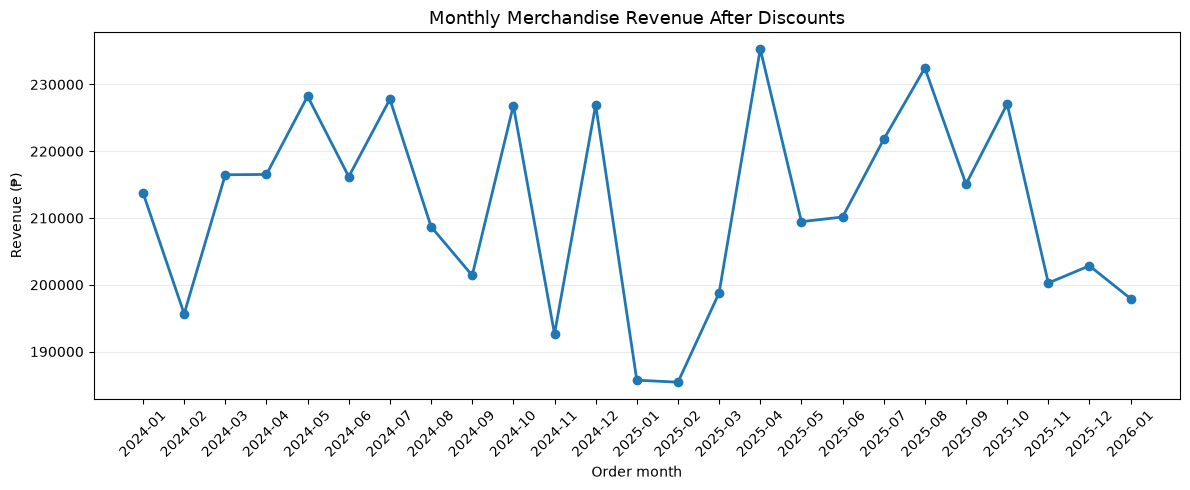

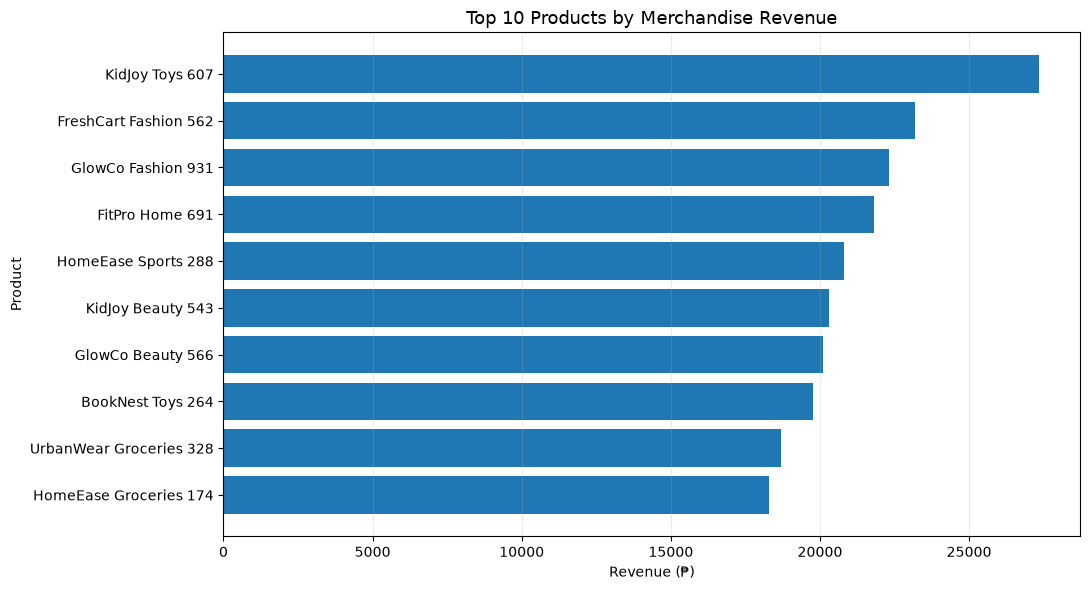

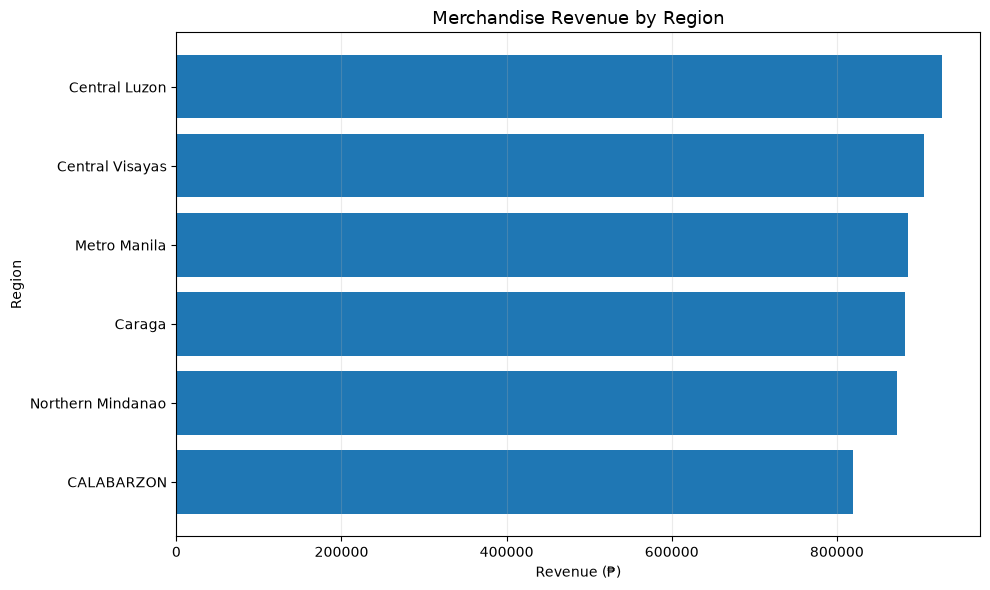

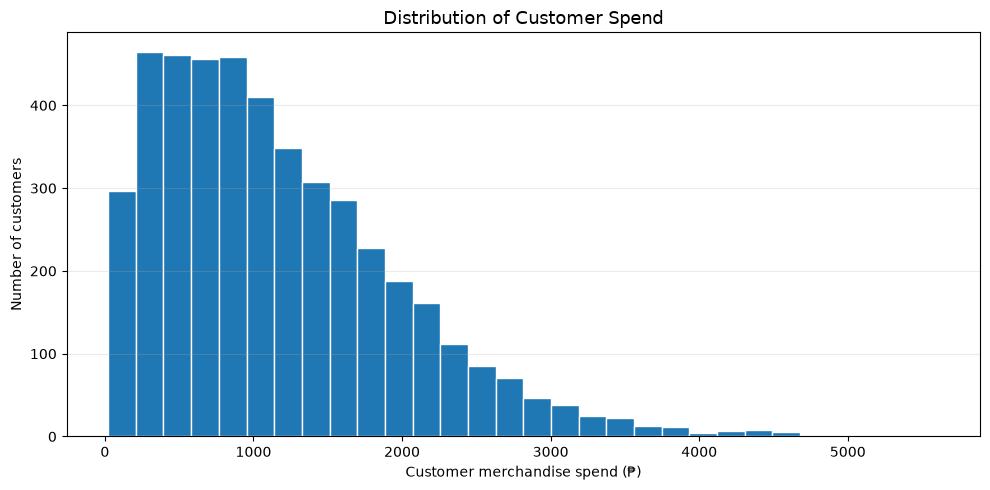

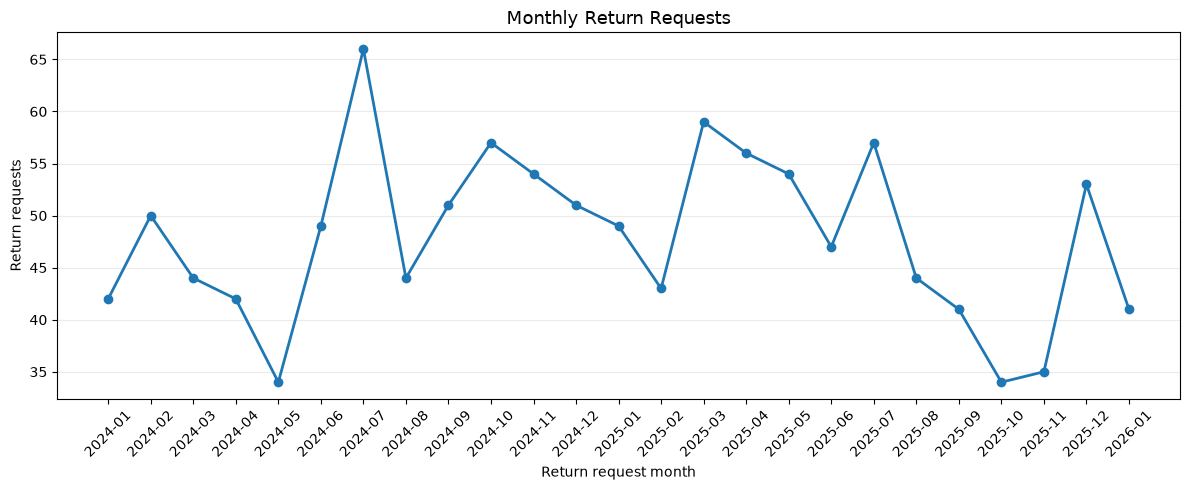

Exported charts: 5


In [15]:
# Chart 1 — Monthly revenue trend
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly_revenue["order_month"], monthly_revenue["revenue"], marker="o", linewidth=2)
ax.set_title("Monthly Merchandise Revenue After Discounts")
ax.set_xlabel("Order month"); ax.set_ylabel("Revenue (₱)"); ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=.25); fig.tight_layout()
fig.savefig(CHART_DIR/"01_monthly_revenue.png", dpi=180, bbox_inches="tight"); plt.show()

# Chart 2 — Top 10 products by revenue
fig, ax = plt.subplots(figsize=(11, 6))
plot_df = top_products.sort_values("revenue")
ax.barh(plot_df["product_name"], plot_df["revenue"])
ax.set_title("Top 10 Products by Merchandise Revenue"); ax.set_xlabel("Revenue (₱)"); ax.set_ylabel("Product")
ax.grid(axis="x", alpha=.25); fig.tight_layout()
fig.savefig(CHART_DIR/"02_top_10_products.png", dpi=180, bbox_inches="tight"); plt.show()

# Chart 3 — Revenue by region
fig, ax = plt.subplots(figsize=(10, 6))
plot_df = region_revenue.sort_values("revenue")
ax.barh(plot_df["region_name"], plot_df["revenue"])
ax.set_title("Merchandise Revenue by Region"); ax.set_xlabel("Revenue (₱)"); ax.set_ylabel("Region")
ax.grid(axis="x", alpha=.25); fig.tight_layout()
fig.savefig(CHART_DIR/"03_revenue_by_region.png", dpi=180, bbox_inches="tight"); plt.show()

# Chart 4 — Customer spend distribution
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(customer_spend["customer_spend"], bins=30, edgecolor="white")
ax.set_title("Distribution of Customer Spend"); ax.set_xlabel("Customer merchandise spend (₱)"); ax.set_ylabel("Number of customers")
ax.grid(axis="y", alpha=.25); fig.tight_layout()
fig.savefig(CHART_DIR/"04_customer_spend_distribution.png", dpi=180, bbox_inches="tight"); plt.show()

# Chart 5 — Monthly return requests
returns_by_month = (returns.dropna(subset=["return_request_date"])
                    .assign(return_month=lambda x: x["return_request_date"].dt.to_period("M").astype("string"))
                    .groupby("return_month", as_index=False)["return_id"].nunique()
                    .rename(columns={"return_id":"return_requests"}).sort_values("return_month"))
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(returns_by_month["return_month"], returns_by_month["return_requests"], marker="o", linewidth=2)
ax.set_title("Monthly Return Requests"); ax.set_xlabel("Return request month"); ax.set_ylabel("Return requests")
ax.tick_params(axis="x", rotation=45); ax.grid(axis="y", alpha=.25); fig.tight_layout()
fig.savefig(CHART_DIR/"05_monthly_returns.png", dpi=180, bbox_inches="tight"); plt.show()

print("Exported charts:", len(list(CHART_DIR.glob("*.png"))))


## 12. Dashboard export (1920 × 1080)

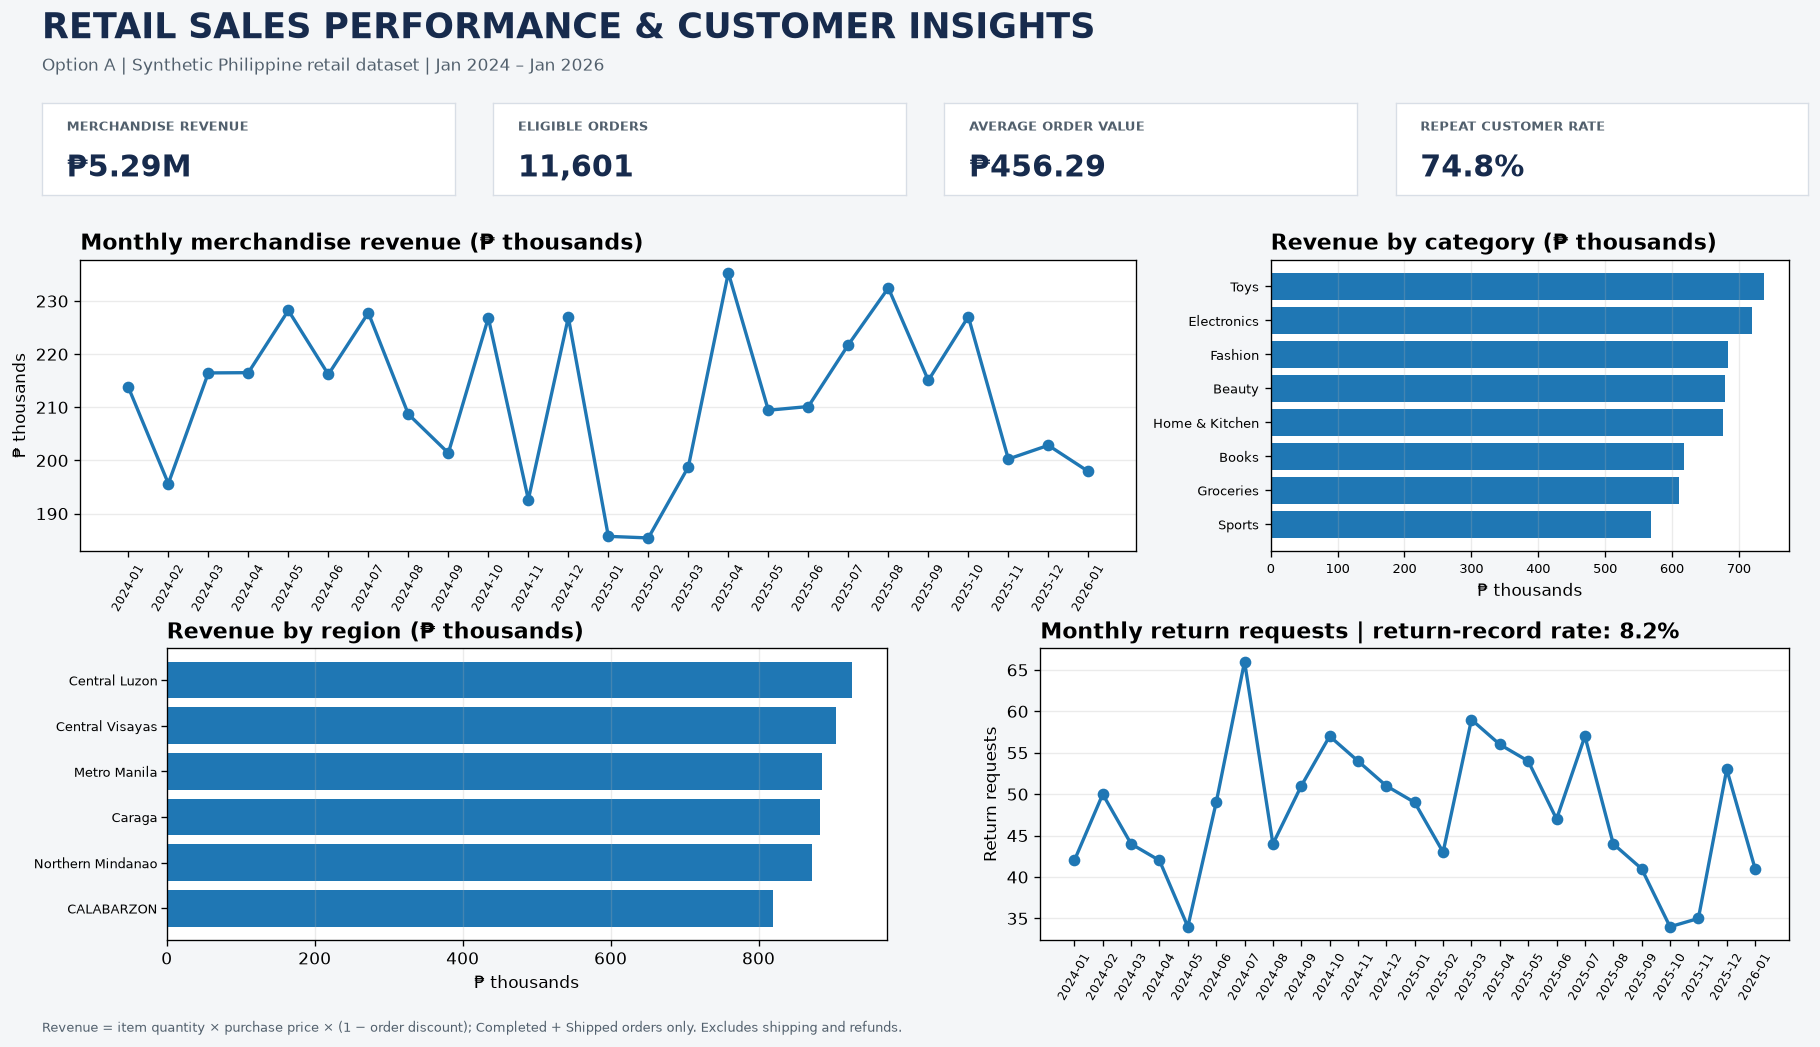

In [16]:
# Create a 16:9 dashboard image at exactly 1920 × 1080 pixels.
fig = plt.figure(figsize=(16, 9), dpi=120, facecolor="#f4f6f8")
fig.text(.04, .955, "RETAIL SALES PERFORMANCE & CUSTOMER INSIGHTS", fontsize=21, fontweight="bold", color="#172b4d")
fig.text(.04, .925, "Option A | Synthetic Philippine retail dataset | Jan 2024 – Jan 2026", fontsize=10, color="#52606d")
kpi_items = [("MERCHANDISE REVENUE", f"₱{total_revenue/1e6:.2f}M"), ("ELIGIBLE ORDERS", f"{total_orders:,}"), ("AVERAGE ORDER VALUE", f"₱{avg_order_value:,.2f}"), ("REPEAT CUSTOMER RATE", f"{repeat_customer_rate:.1%}")]
for i, (label, value) in enumerate(kpi_items):
    ax = fig.add_axes([.04 + i*.235, .81, .215, .085]); ax.set_facecolor("white"); ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values(): spine.set_color("#d8dee6")
    ax.text(.06, .70, label, transform=ax.transAxes, fontsize=8, color="#52606d", fontweight="bold")
    ax.text(.06, .20, value, transform=ax.transAxes, fontsize=18, color="#172b4d", fontweight="bold")
ax1=fig.add_axes([.06,.48,.55,.27]); ax1.plot(monthly_revenue["order_month"], monthly_revenue["revenue"]/1000, marker="o", lw=2); ax1.set_title("Monthly merchandise revenue (₱ thousands)", loc="left", fontweight="bold"); ax1.set_ylabel("₱ thousands"); ax1.tick_params(axis="x", rotation=60, labelsize=7); ax1.grid(axis="y", alpha=.25)
ax2=fig.add_axes([.68,.48,.27,.27]); c=category_revenue.sort_values("revenue"); ax2.barh(c["category"], c["revenue"]/1000); ax2.set_title("Revenue by category (₱ thousands)", loc="left", fontweight="bold"); ax2.set_xlabel("₱ thousands"); ax2.tick_params(labelsize=8); ax2.grid(axis="x", alpha=.25)
ax3=fig.add_axes([.105,.12,.375,.27]); r=region_revenue.sort_values("revenue"); ax3.barh(r["region_name"], r["revenue"]/1000); ax3.set_title("Revenue by region (₱ thousands)", loc="left", fontweight="bold"); ax3.set_xlabel("₱ thousands"); ax3.tick_params(axis="y", labelsize=8, pad=2); ax3.grid(axis="x", alpha=.25)
ax4=fig.add_axes([.56,.12,.39,.27]); ax4.plot(returns_by_month["return_month"], returns_by_month["return_requests"], marker="o", lw=2); ax4.set_title(f"Monthly return requests | return-record rate: {return_rate:.1%}", loc="left", fontweight="bold"); ax4.set_ylabel("Return requests"); ax4.tick_params(axis="x", rotation=60, labelsize=7); ax4.grid(axis="y", alpha=.25)
fig.text(.04,.035,"Revenue = item quantity × purchase price × (1 − order discount); Completed + Shipped orders only. Excludes shipping and refunds.", fontsize=8, color="#52606d")
fig.savefig(OUTPUT_DIR/"dashboard_1920x1080.png", dpi=120, facecolor=fig.get_facecolor())
plt.show()


In [17]:
from PIL import Image

dashboard_path = OUTPUT_DIR / "dashboard_1920x1080.png"

with Image.open(dashboard_path) as img:
    print("Dashboard dimensions:", img.size)
    print("File size:", f"{dashboard_path.stat().st_size / 1024:.1f} KB")

Dashboard dimensions: (1920, 1080)
File size: 201.0 KB


## 12. Additional breakdowns and interpretation support

In [18]:
print("Revenue by category")
display(category_revenue)
print("Revenue by city — top 10")
display(city_revenue.head(10))
print("Repeat vs one-time purchasing customers")
display(pd.DataFrame({"customer_type":["Repeat (2+ orders)","One-time (1 order)"],
                      "customers":[repeat_customers,new_or_one_time_customers]}))
print("Return reasons")
display(returns["reason"].value_counts().rename_axis("reason").reset_index(name="return_records"))


Revenue by category


,category,revenue
7,Toys,"738,320.75"
2,Electronics,"719,343.29"
3,Fashion,"683,244.77"
0,Beauty,"678,927.49"
5,Home & Kitchen,"676,370.38"
1,Books,"617,336.90"
4,Groceries,"610,682.53"
6,Sports,"569,204.01"


Revenue by city — top 10


,city,revenue
14,Olongapo,"340,940.00"
9,Iligan,"319,309.98"
17,San Fernando,"312,113.30"
4,Cagayan de Oro,"280,065.48"
0,Angeles,"273,929.73"
23,Valencia,"273,527.32"
22,Tandag,"263,054.59"
7,Cebu City,"243,054.69"
10,Lapu-Lapu,"232,032.59"
20,Tagbilaran,"215,679.70"


Repeat vs one-time purchasing customers


,customer_type,customers
0,Repeat (2+ orders),3378
1,One-time (1 order),1141


Return reasons


,reason,return_records
0,Changed Mind,182
1,Defective,178
2,Size Issue,174
3,Missing Parts,173
4,Late Delivery,168
5,Wrong Item,162
6,Damaged Item,160


## 13. Data quality validation and cleaning log

In [19]:
# Key checks after cleaning and joining.
validation = pd.DataFrame([
    {"check":"Unique customer_id in cleaned customers", "result":customers["customer_id"].is_unique},
    {"check":"Unique product_id in cleaned products", "result":products["product_id"].is_unique},
    {"check":"Unique order_id in cleaned orders", "result":orders["order_id"].is_unique},
    {"check":"Unique order_item_id in cleaned order items", "result":order_items["order_item_id"].is_unique},
    {"check":"No orphan customer keys in cleaned orders", "result":orders["customer_id"].isin(customers["customer_id"]).all()},
    {"check":"No orphan product keys in cleaned order items", "result":order_items["product_id"].isin(products["product_id"]).all()},
    {"check":"No orphan order keys in cleaned order items", "result":order_items["order_id"].isin(orders["order_id"]).all()},
    {"check":"All fact revenue values are non-negative", "result":fact["discounted_line_revenue"].ge(0).all()},
])
display(validation)
assert validation["result"].all(), "One or more validation checks failed. Review the cleaning steps."

cleaning_log_df = pd.DataFrame(cleaning_log)
display(cleaning_log_df)
cleaning_log_df.to_csv(OUTPUT_DIR/"cleaning_log.csv", index=False)


,check,result
0,Unique customer_id in cleaned customers,True
1,Unique product_id in cleaned products,True
2,Unique order_id in cleaned orders,True
3,Unique order_item_id in cleaned order items,True
4,No orphan customer keys in cleaned orders,True
5,No orphan product keys in cleaned order items,True
6,No orphan order keys in cleaned order items,True
7,All fact revenue values are non-negative,True


,dataset,action,rows_before,rows_after,rows_affected,reason_or_rule
0,customers,Remove exact duplicate rows,5050,5000,50,Exact row match; keep one copy.
1,products,Remove exact duplicate rows,800,800,0,No product duplicates expected; retained uniqu...
2,orders,Remove exact duplicate rows,15075,15000,75,Duplicate order_id rows are exact duplicates a...
3,orders,Remove orders with orphan customer_id,15000,14957,43,Removed 43 orders whose customer_id is absent ...
4,order_items,Remove exact duplicate rows,37763,37501,262,Duplicate order_item_id rows are exact duplica...
5,order_items,Remove non-positive quantities,37501,37129,372,Quantity must be greater than zero.
6,order_items,Backfill missing purchase prices,2217,9,2208,Use matching products.unit_price as a document...
7,order_items,Remove orphan product keys,37129,37002,127,Retain only product_id values present in clean...
8,order_items,Remove orphan order keys,37002,36892,110,Retain only order_id values present in cleaned...
9,order_items,Remove rows with unresolved purchase price,36892,36892,0,No defensible price fallback was available.


## 14. Export cleaned datasets and analytical outputs

In [20]:
customers.to_csv(OUTPUT_DIR/"cleaned_customers.csv", index=False)
products.to_csv(OUTPUT_DIR/"cleaned_products.csv", index=False)
fact.to_csv(OUTPUT_DIR/"sales_fact_table.csv", index=False)
monthly_revenue.to_csv(OUTPUT_DIR/"monthly_revenue.csv", index=False)
top_products.to_csv(OUTPUT_DIR/"top_10_products.csv", index=False)
category_revenue.to_csv(OUTPUT_DIR/"revenue_by_category.csv", index=False)
region_revenue.to_csv(OUTPUT_DIR/"revenue_by_region.csv", index=False)
city_revenue.to_csv(OUTPUT_DIR/"revenue_by_city.csv", index=False)
returns_by_month.to_csv(OUTPUT_DIR/"monthly_returns.csv", index=False)
payments.to_csv(OUTPUT_DIR/"cleaned_payments.csv", index=False)
returns.to_csv(OUTPUT_DIR/"cleaned_returns.csv", index=False)
shipments.to_csv(OUTPUT_DIR/"cleaned_shipments.csv", index=False)
kpis.to_csv(OUTPUT_DIR/"kpi_summary.csv", index=False)
print("Exports saved to:", OUTPUT_DIR.resolve())


Exports saved to: C:\Users\CC2046\Downloads\Option_A_Sales_Performance_Customer_Insights\Option_A_Sales_Performance_Customer_Insights\output


Use the actual values generated above to write 5–8 concise insights and exactly 2 practical recommendations. Do not claim causation from descriptive data. Note that the dataset is synthetic and payment/refund records are not used as the source of sales revenue.

## 16. Evidence-based insights and recommendations

### Key insights
1. Merchandise revenue after discounts was **₱5,293,430.12** across **11,601 eligible orders**; AOV was **₱456.29**.
2. Full-year revenue was approximately **₱2.57M in 2024** and **₱2.52M in 2025**, a modest **1.8% decrease**. January 2026 is a partial year and is not comparable to full years.
3. **Toys** was the highest-revenue category at approximately **₱738,321 (13.9%)**. No category contributed more than 14%, indicating a fairly distributed category mix.
4. **Central Luzon** led regional revenue at approximately **₱926,983 (17.5%)**; the six regions were relatively close in contribution.
5. **3,378 of 4,519 purchasing customers (74.8%)** placed at least two eligible orders.
6. **957 eligible orders (8.2%)** had at least one return record. This is a return-record rate, not a confirmed refund rate.
7. **Changed Mind** was the most frequent return reason (182 of 1,200 source return records), but return reasons were broadly distributed.
8. Web, Mobile App, and Marketplace revenue were closely balanced; no channel overwhelmingly dominated.

### Recommendations
1. Use top-revenue SKUs and the leading Toys/Electronics categories to guide inventory reviews, while checking unit-cost-based margins and stock availability before making purchasing changes.
2. Review return-related product pages, photos, sizing/compatibility information, and pre-dispatch quality checks. Monitor return-record rates by category, product, and channel before attributing causes.

**Interpretation note:** These are descriptive findings from synthetic training data. They do not establish causation. Revenue is calculated from item quantities and purchase prices after order discounts, for Completed and Shipped orders only; shipping fees and refunds are excluded.